In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df=pd.read_csv('/content/placement.csv')

In [ ]:
df.head()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [ ]:
df.shape

(100, 4)

In [ ]:
df.size

400

In [ ]:
df.ndim

2

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  100 non-null    int64  
 1   cgpa        100 non-null    float64
 2   iq          100 non-null    float64
 3   placement   100 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 3.3 KB


In [ ]:
df.dropna()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0
...,...,...,...,...
95,95,4.3,200.0,0
96,96,4.4,42.0,0
97,97,6.7,182.0,1
98,98,6.3,103.0,1


In [ ]:
df=df.iloc[:,1:]

In [ ]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


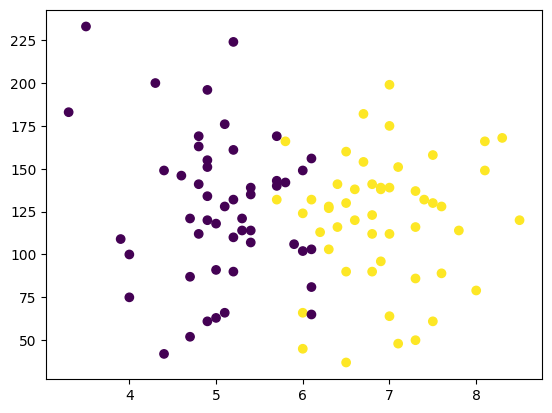

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(df['cgpa'],df['iq'],c=df['placement'])


In [ ]:
X=df.iloc[:,0:2]
y=df.iloc[:,-1]

In [ ]:
X.head()

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0


In [ ]:
y.head()

,placement
0,1
1,0
2,0
3,1
4,0


In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=2)

In [ ]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()

In [ ]:
X_train=sc.fit_transform(X_train)
X_train

array([[ 0.9949909 , -1.88612779],
       [-0.77775872, -0.83863991],
       [ 1.1638242 , -1.83740742],
       [ 0.65732431,  0.69605164],
       [ 0.06640776, -0.57067789],
       [ 1.83915739,  0.98837384],
       [-0.01800889, -0.47323716],
       [-1.62192521, -0.61939826],
       [ 0.57290766,  0.3062887 ],
       [-0.18684218,  0.35500907],
       [ 0.15082441, -1.08224174],
       [-0.18684218,  0.42808962],
       [-0.86217537,  0.62297109],
       [ 1.3326575 ,  0.79349237],
       [ 0.06640776, -1.95920834],
       [-0.44009213,  0.33064889],
       [ 2.00799069,  1.0370942 ],
       [-0.18684218,  0.1601276 ],
       [ 0.40407436,  0.37936925],
       [-1.36867527,  1.81662007],
       [ 0.91057425,  0.33064889],
       [-0.60892543,  0.1601276 ],
       [ 0.91057425,  1.79225988],
       [ 0.8261576 ,  0.33064889],
       [ 1.58590744, -0.27835569],
       [-0.69334208, -1.44764449],
       [-1.28425862, -2.03228889],
       [-2.21284175,  1.40249695],
       [-0.94659202,

In [ ]:
X_test=sc.transform(X_test)
X_test

array([[ 1.3326575 ,  0.11140724],
       [ 1.41707414,  0.06268687],
       [ 0.15082441, -1.47200468],
       [-1.03100867, -0.10783441],
       [-0.60892543,  2.40126447],
       [-1.03100867, -0.93608064],
       [-0.52450878, -0.10783441],
       [ 0.06640776, -0.03475386],
       [-0.60892543, -0.86300009],
       [ 0.40407436, -0.22963533],
       [ 0.23524106, -0.30271588],
       [-0.60892543, -0.37579643],
       [-0.86217537,  0.72041182],
       [ 0.15082441, -0.54631771],
       [ 0.74174095, -0.05911404],
       [ 0.9949909 ,  0.62297109],
       [ 1.24824085,  0.1601276 ],
       [ 0.91057425, -0.32707606],
       [ 1.1638242 ,  0.28192852],
       [ 0.48849101, -0.86300009],
       [ 0.74174095, -0.86300009],
       [ 0.8261576 ,  0.3062887 ],
       [-0.18684218,  1.06145439],
       [ 1.3326575 , -1.56944541],
       [-0.86217537, -1.56944541]])

In [ ]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()

In [ ]:
model.fit(X_train,y_train)

LogisticRegression()

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
y_test

,placement
83,1
30,1
56,0
24,0
16,0
23,0
2,0
27,1
28,0
13,1


In [ ]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.92

<Axes: >

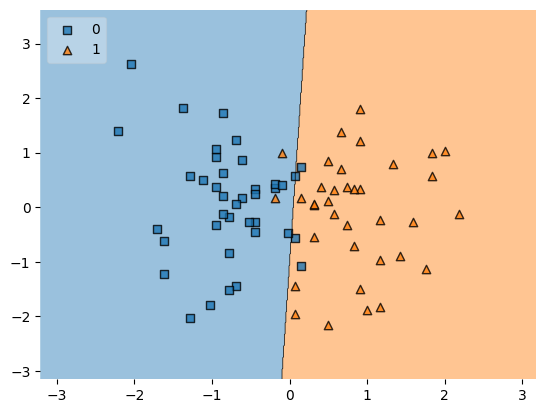

In [ ]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(X_train,y_train.values,clf=model,legend=2)

In [ ]:
import pickle
pickle.dump(model,open('model.pkl','wb'))